[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JoseGG8/AutoEncoderPi/blob/main/modelo/C1/Refinamiento_c1.ipynb)

# 🔬 Comparativa de Circuitos Variacionales — Autoencoder Cuántico (QAE)
### Dataset Paderborn | Detección de Fallas en Rodamientos | Paradigma One-Class

---

## ¿Qué hace este notebook?
Implementa y **compara 7 ansätze (circuitos) variacionales** para el Autoencoder Cuántico.
Para cada circuito calcula:
- **Profundidad y ancho** (complejidad)
- **Visualización del circuito** con `qml.draw_mpl`
- **Curva de convergencia** (fidelidad vs época)
- **Error de reconstrucción** (fidelidad del trash qubit + MSE proxy)

---

## Arquitectura del QAE

```
|ψ_in⟩ (7 qubits, 128 amplitudes)
        │
   ┌────▼────────────────┐
   │   Ansätz  U(θ)      │  ← compuertas parametrizadas (se entrenan)
   └────┬──────────┬─────┘
        │          │
   K latentes   M trash qubits
   (info útil)  └─→ P(|0⟩) = Fidelidad
                    1 - F  = info perdida
```

---

## 📖 Glosario de Compuertas Cuánticas

| Compuerta | Qué hace | Params |
|-----------|----------|--------|
| **RY(θ)** | Rota en eje Y → cambia la **probabilidad** de medir \|0⟩ vs \|1⟩ | 1 |
| **RX(θ)** | Rota en eje X → similar a RY en dirección perpendicular | 1 |
| **RZ(φ)** | Rota en eje Z → cambia la **fase** (interferencia), no las probabilidades | 1 |
| **Rot(φ,θ,ω)** | = RZ·RY·RZ → rotación **arbitraria completa** en la esfera de Bloch | 3 |
| **H** | Hadamard → crea superposición 50-50: \|0⟩→(\|0⟩+\|1⟩)/√2 | 0 |
| **CNOT** | Si control=\|1⟩ aplica NOT al objetivo → **crea entrelazamiento** | 0 |
| **CZ** | Si ambos=\|1⟩ aplica fase -1 → más nativo en hardware superconductor | 0 |
| **IsingZZ(J)** | e^{-iJ·ZZ/2} → acoplamiento magnético cuántico entre vecinos | 1 |
| **IsingXX(J)** | e^{-iJ·XX/2} → acoplamiento en eje X, complementa al ZZ | 1 |


In [ ]:
# Instalar PennyLane si es necesario (descomenta en Colab)
#pip install pennylane -q


SyntaxError: invalid syntax (4156239247.py, line 2)

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split

import pennylane as qml
from pennylane import numpy as pnp

plt.style.use('seaborn-v0_8-whitegrid'
              if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 11})
COLORES = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22']

print(f'PennyLane v{qml.__version__}')


PennyLane v0.45.1


---
## 📦 1. Carga y Preprocesamiento (reutilizado del pipeline principal)

Pipeline: **RobustScaler (P10–P90) → Zero-Padding 128 dims → Normalización L₂**
División: **70% train / 15% val / 15% test** (fit del scaler solo en train). Las salidas guardadas abajo usan la escala anterior; ejecutar el notebook completo para obtener métricas nuevas.


In [3]:
import sys
if os.path.exists('/content') and ('google.colab' in sys.modules):
    if not os.path.exists('/content/drive/MyDrive') and not os.path.exists('/content/drive/My Drive'):
        from google.colab import drive
        drive.mount('/content/drive')

# Rutas posibles (Drive organizada -> Drive respaldo -> Colab -> local solo lectura)
RUTAS = [
    '/content/drive/MyDrive/Paderborn_QML/01_datos/sanos/paderborn_features_tratadas.csv',
    '/content/drive/My Drive/Paderborn_QML/01_datos/sanos/paderborn_features_tratadas.csv',
    '/content/drive/MyDrive/Paderborn_QML/paderborn_features_tratadas.csv',
    '/content/drive/My Drive/Paderborn_QML/paderborn_features_tratadas.csv',
    '/content/drive/MyDrive/Paderborn_QML/VERSION CON ATIPICOS TRATADOS/paderborn_features_tratadas.csv',
    '/content/paderborn_features_tratadas.csv',
    '../../paderborn_features_tratadas.csv',
    '../paderborn_features_tratadas.csv',
    'paderborn_features_tratadas.csv',
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'paderborn_features_tratadas.csv')),
]

ruta = next((r for r in RUTAS if os.path.exists(r)), None)
if ruta is None:
    raise FileNotFoundError('No se encontró paderborn_features_tratadas.csv')

df = pd.read_csv(ruta)
col_label   = 'Label' if 'Label' in df.columns else df.columns[-1]
feature_cols = [c for c in df.columns if c != col_label]
print(f'Dataset: {df.shape[0]} filas x {len(feature_cols)} features | {ruta}')

# ── Partición 70/15/15 ────────────────────────────────────────────────────
X_all = df[feature_cols].values
X_tr, X_tmp = train_test_split(X_all, test_size=0.30, random_state=42)
X_val, X_te = train_test_split(X_tmp, test_size=0.50, random_state=42)

# ── RobustScaler: fit SOLO en train (evita data leakage) ─────────────────
scaler = RobustScaler(quantile_range=(10, 90))  # Evita IQR=0 en condiciones operativas
scaler.fit(X_tr)          # Aprende estadísticas solo de los datos de entrenamiento
X_tr  = scaler.transform(X_tr)
X_val = scaler.transform(X_val)
X_te  = scaler.transform(X_te)

# ── Zero-Padding a 128 dims (2^7 para Amplitude Encoding en 7 qubits) ────
def zero_pad(X, dim=128):
    """Extiende con ceros a la derecha hasta 'dim' dimensiones."""
    pad = dim - X.shape[1]
    return np.hstack([X, np.zeros((len(X), pad))]) if pad > 0 else X

X_tr  = zero_pad(X_tr);  X_val = zero_pad(X_val);  X_te = zero_pad(X_te)

# ── Normalización L2 por fila (condición cuántica: suma |a_i|^2 = 1) ──────
def l2(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.where(n == 0, 1.0, n)  # Evita dividir por cero

X_train_q = l2(X_tr)
X_val_q   = l2(X_val)
X_test_q  = l2(X_te)

print(f'Train: {X_train_q.shape} | Val: {X_val_q.shape} | Test: {X_test_q.shape}')
print(f'Norma L2 media (debe ser ≈1): {np.linalg.norm(X_train_q, axis=1).mean():.6f}')


Dataset: 59867 filas x 71 features | ../paderborn_features_tratadas.csv
Train: (41906, 128) | Val: (8980, 128) | Test: (8981, 128)
Norma L2 media (debe ser ≈1): 1.000000


---
## ⛛️ 2. Los 7 Ansätze Variacionales

| # | Nombre | Idea central | Complejidad |
|---|--------|--------------|-------------|
| C1 | Rot+Stride *(mejorado)* | Rot completo + CNOT de alcance variable por capa (4 capas, 2 trash) | Media |
| C2 | BasicEntangler | Template PennyLane mínimo (RX + CNOT lineal) | Mínima |
| C3 | StronglyEntangling | Rot completo + CNOT no-local por capa | Media-alta |
| C4 | Hardware-Efficient | RY+RZ + CZ lineal (orientado a hardware real) | Media |
| C5 | Two-Design | Hadamard + RY + doble barrido CNOT | Media |
| C6 | Ising-Inspired | RX + IsingZZ + RZ (modelo de spins cuánticos) | Alta |
| C7 | Deep Alternating | Rot + doble CNOT + IsingXX (máxima expresividad) | Muy alta |


In [4]:
# ==============================================================================
# CELDA 3: DEFINICIÓN DE LOS 7 ANSÄTZE
# ==============================================================================
TOTAL_QUBITS = 7  # 2^7 = 128 amplitudes

# ── C1: Rot + CNOT de alcance variable (MEJORADO) ───────────────────────────
def ansatz_c1(weights, wires):
    """
    C1 mejorado. Cambios respecto al baseline RY+RZ + anillo CNOT fijo:
      1) Rot(phi,theta,omega) en vez de RY+RZ -> rotacion arbitraria (3 params/qubit).
      2) CNOT con ALCANCE VARIABLE por capa: capa l conecta qubit i con (i + r) mod n,
         r = (l mod (n-1)) + 1. La capa 0 es el anillo vecino original; las siguientes
         conectan qubits cada vez mas lejanos -> correlaciones no locales sin agregar params.
    weights shape: (n_layers, n_wires, 3)
    """
    n = len(wires)
    for l, layer in enumerate(weights):
        for i, w in enumerate(wires):
            qml.Rot(layer[i, 0], layer[i, 1], layer[i, 2], wires=w)
        r = (l % (n - 1)) + 1
        for i in range(n):
            qml.CNOT(wires=[wires[i], wires[(i + r) % n]])

def ws_c1(nl, nw): return (nl, nw, 3)  # 3 params/qubit/capa


# ── C2: BasicEntanglerLayers ───────────────────────────────────────────────────
def ansatz_c2(weights, wires):
    """
    BasicEntanglerLayers (template PennyLane).
    Solo RX (1 param/qubit) + CNOT lineal. Mínimo de parámetros.
    weights shape: (n_layers, n_wires)
    """
    qml.BasicEntanglerLayers(weights, wires=wires)  # RX + CNOT lineal automático

def ws_c2(nl, nw): return (nl, nw)  # 1 param/qubit/capa


# ── C3: StronglyEntanglingLayers ───────────────────────────────────────────────
def ansatz_c3(weights, wires):
    """
    StronglyEntanglingLayers (template PennyLane).
    Rot(φ,θ,ω) = RZ·RY·RZ (3 params/qubit) + CNOT con patrón variable.
    Crea correlaciones no-locales: qubits no adyacentes quedan entrelazados.
    weights shape: (n_layers, n_wires, 3)
    """
    qml.StronglyEntanglingLayers(weights, wires=wires)  # Rot + CNOT pattern

def ws_c3(nl, nw): return (nl, nw, 3)  # 3 params/qubit/capa

# ── Registro de circuitos ─────────────────────────────────────────────────────
CIRCUITOS = [
    ('C1: Rot+Stride',          ansatz_c1, ws_c1),
    ('C2: BasicEntangler',     ansatz_c2, ws_c2),
    ('C3: StronglyEntangling', ansatz_c3, ws_c3)
]

print('Circuitos registrados:')
for nombre, _, wsfn in CIRCUITOS:
    s = wsfn(2, TOTAL_QUBITS)
    print(f'  {nombre:<28} shape={str(s):<18} params={int(__import__("numpy").prod(s))}')


Circuitos registrados:
  C1: Rot+Stride               shape=(2, 7, 3)          params=42
  C2: BasicEntangler           shape=(2, 7)             params=14
  C3: StronglyEntangling       shape=(2, 7, 3)          params=42


---
## 📐 3. Profundidad, Ancho y Complejidad de cada Circuito

| Métrica | Descripción |
|---------|-------------|
| **Profundidad** | Capas secuenciales máximas. Mayor = más expresivo pero más ruido en hardware |
| **Ancho** | Número de qubits (siempre 7 aquí) |
| **Nº parámetros** | Parámetros entrenables (equivalente a los pesos de una red neuronal) |
| **Total puertas** | Operaciones cuánticas aplicadas |


In [5]:
# ==============================================================================
# CELDA 4: MÉTRICAS DE COMPLEJIDAD — qml.specs()
# ==============================================================================

def calcular_metricas(nombre, ansatz_fn, ws_fn, n_layers=2, n_wires=7, trash=1):
    """Extrae profundidad, numero de puertas y params usando qml.specs().

    Compatibilidad: qml.specs() devuelve un objeto 'resources' cuya API
    varía entre versiones de PennyLane. Aquí se accede de forma defensiva.
    """
    dev_t = qml.device('default.qubit', wires=n_wires)
    tw    = list(range(n_wires - trash, n_wires))
    shape = ws_fn(n_layers, n_wires)
    w0    = np.zeros(shape)                                      # Pesos dummy (estructura)
    sv0   = np.ones(2**n_wires) / np.sqrt(2**n_wires)           # Estado uniforme de referencia
    n_par = int(np.prod(shape))                                  # Total parámetros entrenables

    @qml.qnode(dev_t)
    def circ(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        ansatz_fn(w, wires=range(n_wires))
        return qml.probs(wires=tw)

    specs = qml.specs(circ)(sv0, w0)
    res   = specs['resources']

    # ── Profundidad: capas secuenciales máximas ───────────────────────────────
    depth = res.depth

    # ── Total de puertas: compatible con distintas versiones de PennyLane ────
    # Versiones antiguas: res.num_gates (int)
    # Versiones nuevas:   res.gate_sizes (dict {n_qubits: count}) o res.gate_types
    if hasattr(res, 'num_gates'):
        total_gates = res.num_gates
    elif hasattr(res, 'gate_sizes'):
        total_gates = sum(res.gate_sizes.values())  # Suma todos los tamaños de puerta
    else:
        total_gates = sum(res.gate_types.values())  # Alternativa: suma por tipo

    return {
        'Circuito':       nombre,
        'Profundidad':    depth,
        'Ancho (qubits)': n_wires,          # Fijo = 7 en este proyecto
        'Nº Parámetros':  n_par,
        'Total Puertas':  total_gates,
        'Línea Base (%)': round(100.0 / (2**trash), 1),
    }

np.random.seed(0)
tabla_comp = [calcular_metricas(n, fn, ws) for n, fn, ws in CIRCUITOS]
df_comp    = pd.DataFrame(tabla_comp).set_index('Circuito')

print(df_comp.to_string())


                        Profundidad  Ancho (qubits)  Nº Parámetros  Total Puertas  Línea Base (%)
Circuito                                                                                         
C1: Rot+Stride                   14               7             42             29            50.0
C2: BasicEntangler                2               7             14              2            50.0
C3: StronglyEntangling            2               7             42              2            50.0


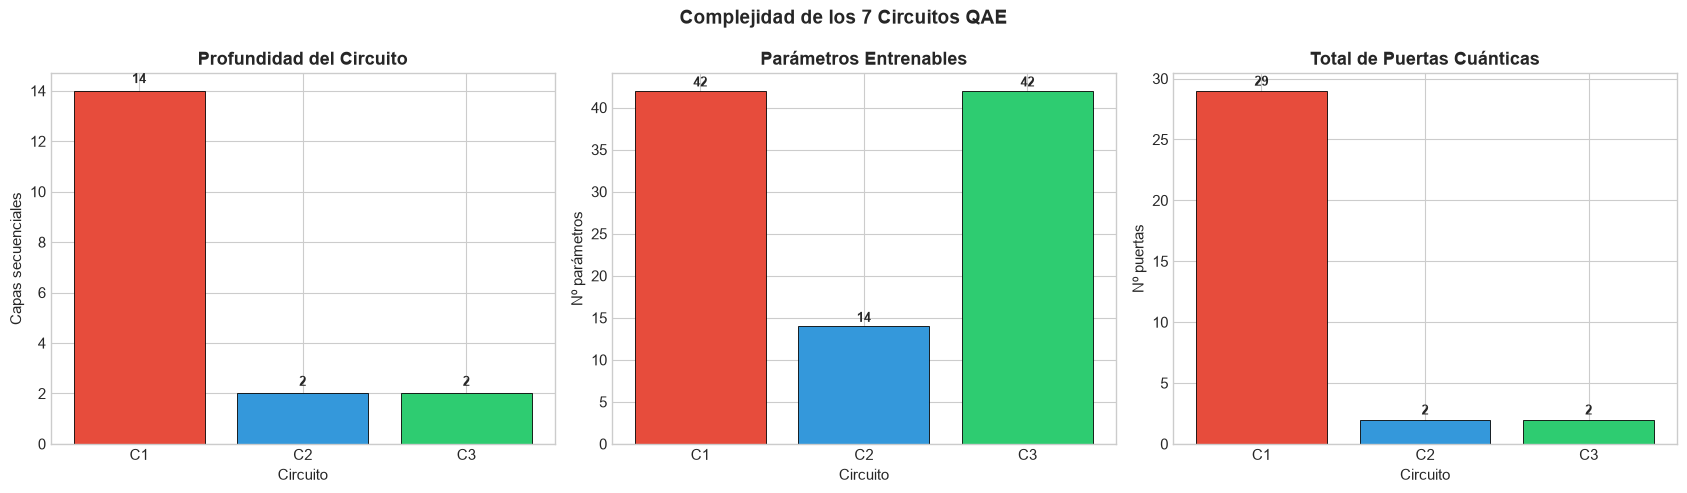

Guardado: complejidad_circuitos.png


In [6]:
# ==============================================================================
# CELDA 5: GRÁFICA — PROFUNDIDAD, PARÁMETROS Y PUERTAS POR CIRCUITO
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Complejidad de los 7 Circuitos QAE', fontsize=14, fontweight='bold')

etiq = [n.split(':')[0] for n in df_comp.index]  # C1, C2, ...
metr = ['Profundidad', 'Nº Parámetros', 'Total Puertas']
tits = ['Profundidad del Circuito', 'Parámetros Entrenables', 'Total de Puertas Cuánticas']
ylabs = ['Capas secuenciales', 'Nº parámetros', 'Nº puertas']

for ax, col, tit, yl in zip(axes, metr, tits, ylabs):
    bars = ax.bar(etiq, df_comp[col], color=COLORES, edgecolor='black', linewidth=0.6)
    ax.set_title(tit, fontweight='bold')
    ax.set_ylabel(yl)
    ax.set_xlabel('Circuito')
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.2,
                str(int(b.get_height())), ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


---
## 🖼️ 4. Diagrama de cada Circuito

Cada línea horizontal = un qubit. Las cajas = compuertas. Las líneas verticales = entrelazamiento (CNOT, CZ, Ising...).

> Visualización con 2 capas y 7 qubits (1 trash qubit, K=6 latentes).


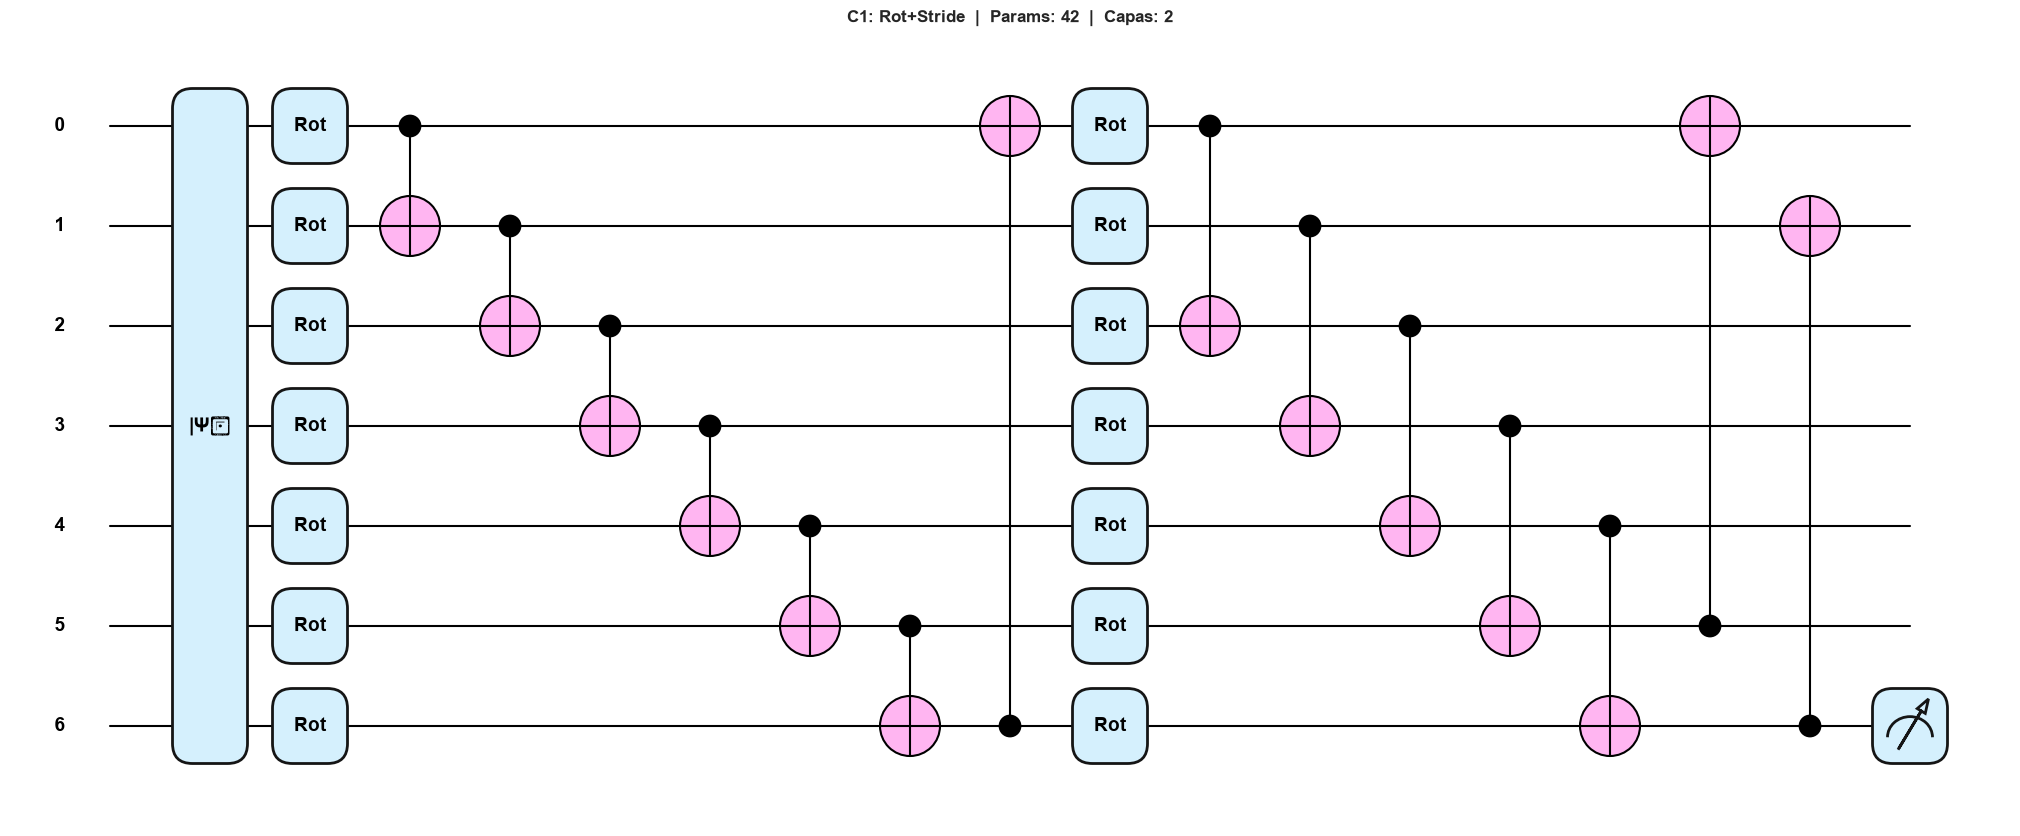

  Guardado: circuito_1_C1.png


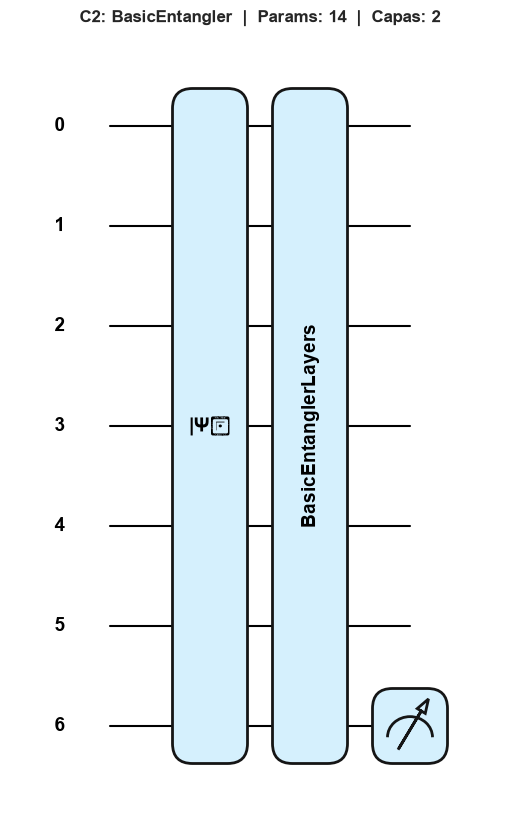

  Guardado: circuito_2_C2.png


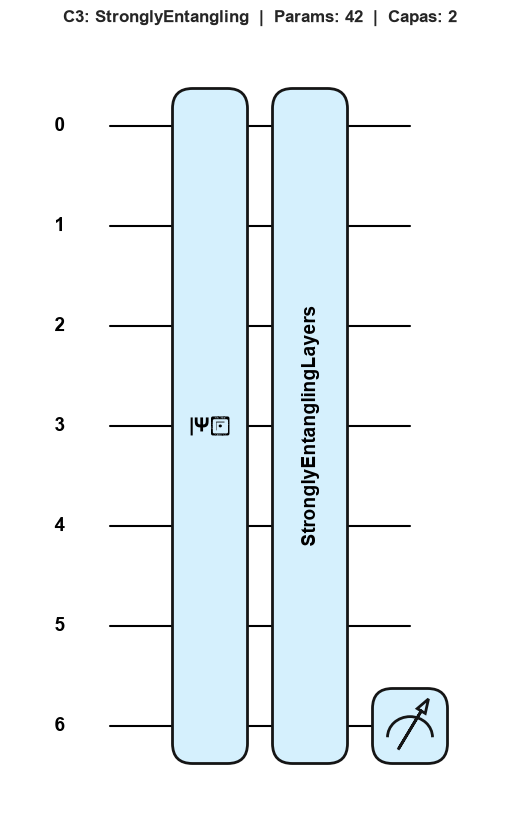

  Guardado: circuito_3_C3.png


In [7]:
# ==============================================================================
# CELDA 6: DIAGRAMAS DE CIRCUITO CON qml.draw_mpl()
# ==============================================================================

NL_VIZ, NW_VIZ, TR_VIZ = 2, 7, 1
np.random.seed(0)
sv_viz = np.ones(2**NW_VIZ) / np.sqrt(2**NW_VIZ)  # Estado uniforme de demo
tw_viz = list(range(NW_VIZ - TR_VIZ, NW_VIZ))

for idx, (nombre, ansatz_fn, ws_fn) in enumerate(CIRCUITOS):
    shape  = ws_fn(NL_VIZ, NW_VIZ)
    w_viz  = np.zeros(shape)
    dev_v  = qml.device('default.qubit', wires=NW_VIZ)

    @qml.qnode(dev_v)
    def circ_viz(sv, w, afn=ansatz_fn, tw=tw_viz, nw=NW_VIZ):
        qml.AmplitudeEmbedding(sv, wires=range(nw), normalize=False)
        afn(w, wires=range(nw))
        return qml.probs(wires=tw)

    fig, ax = qml.draw_mpl(circ_viz, style='pennylane')(sv_viz, w_viz)
    n_par   = int(np.prod(shape))
    fig.suptitle(f'{nombre}  |  Params: {n_par}  |  Capas: {NL_VIZ}',
                 fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


---
## 🏋️ 5. Entrenamiento Comparativo

Condiciones iguales para todos:
- **100 registros** de entrenamiento (Fase 1 — prototipo)
- **20 épocas**, batch 25, Adam lr=0.12
- **1 trash qubit** (K=6 latentes, línea base aleatoria = 50%)

> ⚠️ En CPU puede tardar varios minutos. En Google Colab con GPU es mucho más rápido.

### Función de costo
$$\mathcal{L}(\theta) = 1 - \mathbb{E}[P(|0\rangle^M_{\text{trash}})]$$

El objetivo es **maximizar la fidelidad** — que los trash qubits vuelvan a |0⟩,
lo que significa que TODA la info relevante quedó en los K qubits latentes.


In [15]:
# ==============================================================================
# CELDA 7: FUNCIÓN DE ENTRENAMIENTO REUTILIZABLE
# ==============================================================================

def entrenar_qae(nombre, ansatz_fn, ws_fn, X_tr, X_val,
                 n_layers=2, n_wires=7, trash=1,
                 epochs=20, batch=25, lr=0.12, n_samp=100, seed=42):
    """
    Entrena un QAE y devuelve historial de pérdidas/fidelidades.

    Retorna dict con: weights, qnode, fidelidad_fn, history, linea_base, n_params
    """
    np.random.seed(seed)
    dev   = qml.device('default.qubit', wires=n_wires)  # Simulador clásico de qubits
    tw    = list(range(n_wires - trash, n_wires))        # Índices de trash qubits
    shape = ws_fn(n_layers, n_wires)

    # Pesos iniciales aleatorios en [0, 2π] — requires_grad activa el cálculo de gradientes
    W = pnp.random.uniform(0.0, 2*np.pi, size=shape, requires_grad=True)

    @qml.qnode(dev)
    def qnode(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        # AmplitudeEmbedding: codifica el vector clásico normalizado como estado cuántico
        ansatz_fn(w, wires=range(n_wires))   # Aplica el circuito variacional
        return qml.probs(wires=tw)            # P de cada estado posible en los trash qubits

    fid   = lambda sv, w: float(qnode(sv, w)[0])  # F = P(|0>) en trash

    def loss_b(w, B):
        return 1.0 - pnp.mean(qnode(B, w)[:, 0])  # 1 - F media (batch vectorizado, ~10x mas rapido)

    X_demo = X_tr[:n_samp]
    opt    = qml.AdamOptimizer(stepsize=lr)  # Adam cuántico de PennyLane
    hist   = {'loss':[], 'fid_tr':[], 'fid_val':[]}
    lb     = 100.0 / (2**trash)

    print(f'\n[{nombre}]  params={int(np.prod(shape))}  trash={trash}  base={lb:.0f}%')

    for ep in range(epochs):
        perm = np.random.permutation(len(X_demo))
        ep_loss = []
        for i in range(0, len(X_demo), batch):
            B = X_demo[perm[i:i+batch]]
            W, cost = opt.step_and_cost(lambda w: loss_b(w, B), W)
            # step_and_cost: calcula gradiente y actualiza pesos en un solo paso
            ep_loss.append(float(cost))
        avg_l   = float(np.mean(ep_loss))
        fid_val = float(np.mean([fid(sv, W) for sv in X_val[:15]])) * 100
        hist['loss'].append(avg_l)
        hist['fid_tr'].append((1-avg_l)*100)
        hist['fid_val'].append(fid_val)
        if (ep+1) % 5 == 0 or ep == 0:
            print(f'  ep {ep+1:02d} | loss={avg_l:.4f} | '
                  f'train={hist["fid_tr"][-1]:.1f}% | val={fid_val:.1f}%')

    print(f'  Final → train={hist["fid_tr"][-1]:.1f}%  val={hist["fid_val"][-1]:.1f}%')
    return dict(nombre=nombre, weights=W, qnode=qnode, fid=fid,
                history=hist, lb=lb, n_params=int(np.prod(shape)), trash=trash)


In [16]:
# ==============================================================================
# CELDA 8: ENTRENAR LOS CIRCUITOS
# ==============================================================================
CFG = dict(n_layers=2, n_wires=7, trash=1, epochs=20,
           batch=25, lr=0.12, n_samp=100, seed=42)

# Overrides por circuito (solo C1 por ahora). Ajusta aqui con lo que encuentres
# en la celda de experimentacion (seccion 9).
CFG_POR_CIRCUITO = {
    'C1: Rot+Stride': dict(n_layers=4, trash=2),
}

resultados = {}
for nombre, afn, wsfn in CIRCUITOS:
    cfg = {**CFG, **CFG_POR_CIRCUITO.get(nombre, {})}
    resultados[nombre] = entrenar_qae(nombre, afn, wsfn, X_train_q, X_val_q, **cfg)

print('\nEntrenamiento completo.')



[C1: Rot+Stride]  params=84  trash=2  base=25%
  ep 01 | loss=0.6725 | train=32.8% | val=44.7%
  ep 05 | loss=0.4302 | train=57.0% | val=56.6%
  ep 10 | loss=0.3308 | train=66.9% | val=62.2%
  ep 15 | loss=0.2768 | train=72.3% | val=73.2%
  ep 20 | loss=0.1916 | train=80.8% | val=78.0%
  Final → train=80.8%  val=78.0%

[C2: BasicEntangler]  params=14  trash=1  base=50%
  ep 01 | loss=0.4914 | train=50.9% | val=52.0%
  ep 05 | loss=0.4758 | train=52.4% | val=53.0%
  ep 10 | loss=0.4608 | train=53.9% | val=50.9%
  ep 15 | loss=0.4600 | train=54.0% | val=50.7%
  ep 20 | loss=0.4597 | train=54.0% | val=50.7%
  Final → train=54.0%  val=50.7%

[C3: StronglyEntangling]  params=42  trash=1  base=50%
  ep 01 | loss=0.4427 | train=55.7% | val=64.1%
  ep 05 | loss=0.2774 | train=72.3% | val=74.9%
  ep 10 | loss=0.2365 | train=76.3% | val=80.0%
  ep 15 | loss=0.2340 | train=76.6% | val=80.9%
  ep 20 | loss=0.2331 | train=76.7% | val=81.0%
  Final → train=76.7%  val=81.0%

Entrenamiento completo.


---
## 📈 6. Curvas de Convergencia

La **línea punteada gris** es la fidelidad aleatoria pre-entrenamiento (50% para 1 trash qubit).
Un buen circuito sube sostenidamente por encima de esa línea.


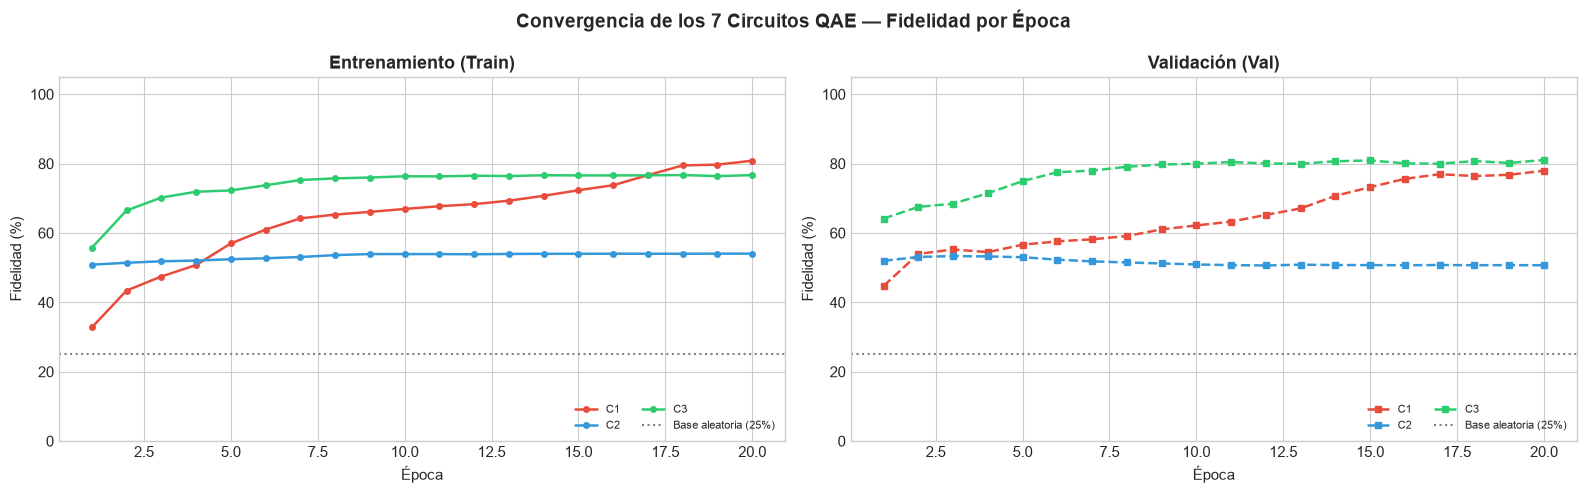

Guardado: convergencia_circuitos.png


In [17]:
# ==============================================================================
# CELDA 9: GRÁFICA DE CONVERGENCIA (Train + Val)
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Convergencia de los 7 Circuitos QAE — Fidelidad por Época',
             fontsize=14, fontweight='bold')
lb_val = list(resultados.values())[0]['lb']

for (nombre, res), col in zip(resultados.items(), COLORES):
    h   = res['history']
    eps = range(1, len(h['fid_tr']) + 1)
    lbl = nombre.split(':')[0]
    ax1.plot(eps, h['fid_tr'],  'o-',  color=col, label=lbl, lw=1.8, ms=4)
    ax2.plot(eps, h['fid_val'], 's--', color=col, label=lbl, lw=1.8, ms=4)

for ax, tit in [(ax1,'Entrenamiento (Train)'), (ax2,'Validación (Val)')]:
    ax.axhline(lb_val, color='gray', ls=':', lw=1.5, label=f'Base aleatoria ({lb_val:.0f}%)')
    ax.set_xlabel('Época'); ax.set_ylabel('Fidelidad (%)'); ax.set_ylim(0, 105)
    ax.set_title(tit, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()


---
## 🔍 7. Error de Reconstrucción: Fidelidad del Trash Qubit vs MSE

**¿Necesitamos un decoder explícito?** No es obligatorio. Aquí la explicación:

| Métrica | Fórmula | Significado |
|---------|---------|-------------|
| **Fidelidad** $F$ | $P(|0\rangle^M)$ | Qué tan bien se comprimió la info |
| **Error de reconstrucción** | $1 - F$ | Fracción de info perdida en los trash qubits |
| **MSE proxy** | $\overline{1-F}$ sobre el test set | Análogo al MSE input/output del decoder clásico |

La fidelidad del trash qubit **ya es** el error de reconstrucción cuántico.
`1 - F` mide exactamente cuánta información se 'fugó' a los qubits descartados.
Para conectar con el lenguaje del profesor, exponemos ambas métricas.


In [18]:
# ==============================================================================
# CELDA 10: EVALUACIÓN CON FALLAS REALES DE PADERBORN (Y DESGLOSE POR FALLA)
# ==============================================================================
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             matthews_corrcoef)

USAR_FALLAS_REALES = True   # True: carga salida de ETL_inicial.ipynb | False: sintéticas
N_POR_TIPO_FALLA   = 100    # Muestras por tipo de falla real (100x3 = 300 fallas vs 300 sanos)
EVAL_SEED          = 42

def hacer_anomalias(X, seed=7):
    np.random.seed(seed)
    Xan = X.copy()
    Xan[:, 10:25] += np.random.normal(0.4, 0.1, Xan[:, 10:25].shape)
    return l2(Xan)

def _buscar_archivo(candidatos):
    return next((p for p in candidatos if os.path.exists(p)), None)

def cargar_todas_fallas_reales(scaler, feature_cols):
    """Carga todas las fallas reales de ETL_inicial (Label==1) en el espacio cuántico de 128 dims."""
    import sys
    if os.path.exists('/content') and ('google.colab' in sys.modules):
        if not os.path.exists('/content/drive/MyDrive') and not os.path.exists('/content/drive/My Drive'):
            from google.colab import drive
            drive.mount('/content/drive')
    ruta_csv = _buscar_archivo([
        '/content/drive/MyDrive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_tratadas.csv',
        '/content/drive/My Drive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_tratadas.csv',
        '/content/drive/MyDrive/Paderborn_QML/paderborn_fallas_tratadas.csv',
        '/content/drive/My Drive/Paderborn_QML/paderborn_fallas_tratadas.csv',
        '/content/paderborn_fallas_tratadas.csv',
        '../../ETL_inicial/paderborn_fallas_tratadas.csv',
        '../ETL_inicial/paderborn_fallas_tratadas.csv',
        'paderborn_fallas_tratadas.csv',
    ])
    ruta_npz = _buscar_archivo([
        '/content/drive/MyDrive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_cuantico_128.npz',
        '/content/drive/My Drive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_cuantico_128.npz',
        '/content/drive/MyDrive/Paderborn_QML/paderborn_fallas_cuantico_128.npz',
        '/content/drive/My Drive/Paderborn_QML/paderborn_fallas_cuantico_128.npz',
        '/content/paderborn_fallas_cuantico_128.npz',
        '../../ETL_inicial/paderborn_fallas_cuantico_128.npz',
        '../ETL_inicial/paderborn_fallas_cuantico_128.npz',
        'paderborn_fallas_cuantico_128.npz',
    ])
    ruta_meta = _buscar_archivo([
        '/content/drive/MyDrive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_metadatos.csv',
        '/content/drive/My Drive/Paderborn_QML/01_datos/fallas_reales/paderborn_fallas_metadatos.csv',
        '/content/drive/MyDrive/Paderborn_QML/paderborn_fallas_metadatos.csv',
        '/content/drive/My Drive/Paderborn_QML/paderborn_fallas_metadatos.csv',
        '/content/paderborn_fallas_metadatos.csv',
        '../../ETL_inicial/paderborn_fallas_metadatos.csv',
        '../ETL_inicial/paderborn_fallas_metadatos.csv',
        'paderborn_fallas_metadatos.csv',
    ])

    if ruta_csv is not None:
        df_f = pd.read_csv(ruta_csv)
        assert list(df_f[feature_cols].columns) == feature_cols, 'Columnas de fallas no coinciden.'
        y_all = df_f['Label'].values.astype(int)
        X_all_f = l2(zero_pad(scaler.transform(df_f[feature_cols].values)))
        fuente = ruta_csv
    elif ruta_npz is not None:
        data = np.load(ruta_npz, allow_pickle=True)
        if 'scaler_quantile_range' not in data or not np.array_equal(data['scaler_quantile_range'], [10, 90]):
            raise ValueError('NPZ con escala anterior: usa paderborn_fallas_tratadas.csv o regenera el ETL.')
        X_all_f = data['X_q']
        y_all = data['y'].astype(int)
        fuente = ruta_npz
    else:
        raise FileNotFoundError(
            'No se encontró paderborn_fallas_tratadas.csv ni paderborn_fallas_cuantico_128.npz. '
            'Ejecuta primero ETL_inicial/ETL_inicial.ipynb.'
        )

    if ruta_meta is not None:
        meta = pd.read_csv(ruta_meta)
        tipos_all = meta['Tipo_Falla'].values
    elif ruta_npz is not None:
        data_npz = np.load(ruta_npz, allow_pickle=True)
        tipos_all = data_npz['tipo_falla'] if 'tipo_falla' in data_npz else np.array(['Falla_Real'] * len(y_all))
    else:
        tipos_all = np.array(['Falla_Real'] * len(y_all))

    mask_falla = (y_all == 1)
    X_fallas = X_all_f[mask_falla]
    tipos_fallas = tipos_all[mask_falla]
    if len(X_fallas) == 0:
        raise ValueError('El archivo de fallas no contiene registros con Label == 1.')
    print(f'Fallas reales cargadas desde: {fuente} ({len(X_fallas)} ventanas Label=1)')
    return X_fallas, tipos_fallas

def muestra_estratificada_fallas(X_fallas, tipos_fallas, n_total=None, n_por_tipo=None, seed=42):
    """Selecciona una muestra estratificada por Tipo_Falla."""
    rng = np.random.default_rng(seed)
    clases = sorted(np.unique(tipos_fallas))
    if n_por_tipo is None:
        n_por_tipo = max(1, int(np.ceil(n_total / len(clases))))
    indices_sel = []
    for tipo in clases:
        idx_t = np.where(tipos_fallas == tipo)[0]
        k = min(n_por_tipo, len(idx_t))
        indices_sel.extend(rng.choice(idx_t, size=k, replace=False))
    indices_sel = np.array(indices_sel, dtype=int)
    if n_total is not None and len(indices_sel) > n_total:
        indices_sel = rng.choice(indices_sel, size=n_total, replace=False)
    return X_fallas[indices_sel], tipos_fallas[indices_sel]

def fidelidades_batch(qnode, W, X, batch_size=200):
    fids = []
    for i in range(0, len(X), batch_size):
        B = pnp.array(X[i:i + batch_size], requires_grad=False)
        fids.append(np.asarray(qnode(B, W)[:, 0], dtype=float))
    return np.concatenate(fids)

def metricas_deteccion(err_s, err_a, tau=None):
    """
    Métricas de detección. Clase positiva = ANOMALÍA / FALLA (1), negativa = SANO (0).
    Score = error de reconstrucción (1 - F); se predice falla si score > tau.
    tau por defecto = percentil 95 del error en sanos (~5 % de falsos positivos esperados).
    """
    err_s = np.asarray(err_s, dtype=float); err_a = np.asarray(err_a, dtype=float)
    if tau is None:
        tau = np.percentile(err_s, 95)
    y_true = np.r_[np.zeros(len(err_s)), np.ones(len(err_a))].astype(int)
    score  = np.r_[err_s, err_a]
    y_pred = (score > tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / b if b > 0 else 0.0
    tpr  = div(tp, tp + fn)
    tnr  = div(tn, tn + fp)
    prec = div(tp, tp + fp)
    return {
        'tau': float(tau), 'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'TPR': tpr * 100, 'FPR': div(fp, fp + tn) * 100, 'TNR': tnr * 100, 'FNR': div(fn, fn + tp) * 100,
        'Precision': prec * 100, 'F1': div(2 * prec * tpr, prec + tpr) * 100,
        'Exactitud': div(tp + tn, tp + tn + fp + fn) * 100,
        'Exactitud_bal': (tpr + tnr) / 2 * 100,
        'MCC': float(matthews_corrcoef(y_true, y_pred)),
        'AUC_ROC': float(roc_auc_score(y_true, score)),
        'AP': float(average_precision_score(y_true, score)),
    }

if USAR_FALLAS_REALES:
    X_fallas_real_all, tipos_fallas_real_all = cargar_todas_fallas_reales(scaler, feature_cols)
    X_anom, tipos_anom = muestra_estratificada_fallas(
        X_fallas_real_all, tipos_fallas_real_all, n_por_tipo=N_POR_TIPO_FALLA, seed=EVAL_SEED
    )
    N_EVAL = min(len(X_anom), len(X_test_q))
    X_anom, tipos_anom = X_anom[:N_EVAL], tipos_anom[:N_EVAL]
    etiqueta_anom = 'Fallas Reales'
else:
    N_EVAL = 50
    X_anom = hacer_anomalias(X_test_q[:N_EVAL])
    tipos_anom = np.array(['Sintetica'] * N_EVAL)
    etiqueta_anom = 'Anomalías Sintéticas'

X_sanos_eval = X_test_q[:N_EVAL]
print(f'Evaluando {N_EVAL} sanos (X_test_q) vs {len(X_anom)} {etiqueta_anom}...\n')

rows, rows_tipo = [], []
scores = {}   # nombre -> (err_sanos, err_anomalias, tau)
for nombre, res in resultados.items():
    qn = res['qnode']
    W  = res['weights']

    fids_s = fidelidades_batch(qn, W, X_sanos_eval)
    fids_a = fidelidades_batch(qn, W, X_anom)
    fid_s  = float(np.mean(fids_s)) * 100
    fid_a  = float(np.mean(fids_a)) * 100
    mse_s  = 1.0 - float(np.mean(fids_s))

    err_s = 1.0 - fids_s
    err_a = 1.0 - fids_a
    m = metricas_deteccion(err_s, err_a)
    scores[nombre] = (err_s, err_a, m['tau'])

    rows.append({
        'Circuito':          nombre,
        'Fid. Sanos (%)':    round(fid_s, 2),
        'Fid. Anomalías (%)': round(fid_a, 2),
        'Separación (pp)':   round(fid_s - fid_a, 2),
        'MSE Proxy (sanos)': round(mse_s, 4),
        'Detección (%)':     round(m['TPR'], 1),
        'FPR (%)':           round(m['FPR'], 1),
        'Precisión (%)':     round(m['Precision'], 1),
        'F1 (%)':            round(m['F1'], 1),
        'Exactitud (%)':     round(m['Exactitud'], 1),
        'Exact. Bal. (%)':   round(m['Exactitud_bal'], 1),
        'MCC':               round(m['MCC'], 3),
        'AUC-ROC':           round(m['AUC_ROC'], 3),
        'AP':                round(m['AP'], 3),
        'TP': m['TP'], 'FP': m['FP'], 'TN': m['TN'], 'FN': m['FN'],
    })
    print(f'  {nombre:<28} sanos={fid_s:.1f}%  fallas={fid_a:.1f}%  '
          f'sep={fid_s-fid_a:.1f}pp  detec={m["TPR"]:.1f}%  FPR={m["FPR"]:.1f}%  '
          f'F1={m["F1"]:.1f}%  AUC={m["AUC_ROC"]:.3f}')

    for tipo in sorted(np.unique(tipos_anom)):
        mask_t = (tipos_anom == tipo)
        mt = metricas_deteccion(err_s, err_a[mask_t], tau=m['tau'])
        fid_t = float(np.mean(fids_a[mask_t])) * 100
        rows_tipo.append({
            'Circuito': nombre.split(':')[0],
            'Tipo_Falla': tipo,
            'N': int(mask_t.sum()),
            'Fid. Falla (%)': round(fid_t, 2),
            'Sep (pp)': round(fid_s - fid_t, 2),
            'TPR (%)': round(mt['TPR'], 1),
            'F1 (%)': round(mt['F1'], 1),
            'AUC-ROC': round(mt['AUC_ROC'], 3),
        })

df_eval = pd.DataFrame(rows).set_index('Circuito')
print('\nRESUMEN GLOBAL:')
print(df_eval.T.to_string())

df_eval_tipo = pd.DataFrame(rows_tipo)
print('\nDESGLOSE POR TIPO DE FALLA REAL (mismo umbral tau = P95 de sanos):')
print(df_eval_tipo.to_string(index=False))


  C1: Rot+Stride               sanos=83.6%  anom=45.8%  sep=37.7pp  detec=100%  FPR=6%  F1=97%  AUC=1.000
  C2: BasicEntangler           sanos=53.2%  anom=54.8%  sep=-1.6pp  detec=0%  FPR=6%  F1=0%  AUC=0.464
  C3: StronglyEntangling       sanos=78.8%  anom=70.4%  sep=8.3pp  detec=0%  FPR=6%  F1=0%  AUC=0.805

 Circuito            C1: Rot+Stride  C2: BasicEntangler  C3: StronglyEntangling
Fid. Sanos (%)             83.5900             53.2100                 78.7800
Fid. Anomalías (%)         45.8500             54.8100                 70.4400
Separación (pp)            37.7500             -1.6000                  8.3300
MSE Proxy (sanos)           0.1641              0.4679                  0.2122
Detección (%)             100.0000              0.0000                  0.0000
FPR (%)                     6.0000              6.0000                  6.0000
Precisión (%)              94.3000              0.0000                  0.0000
F1 (%)                     97.1000              0.0000 

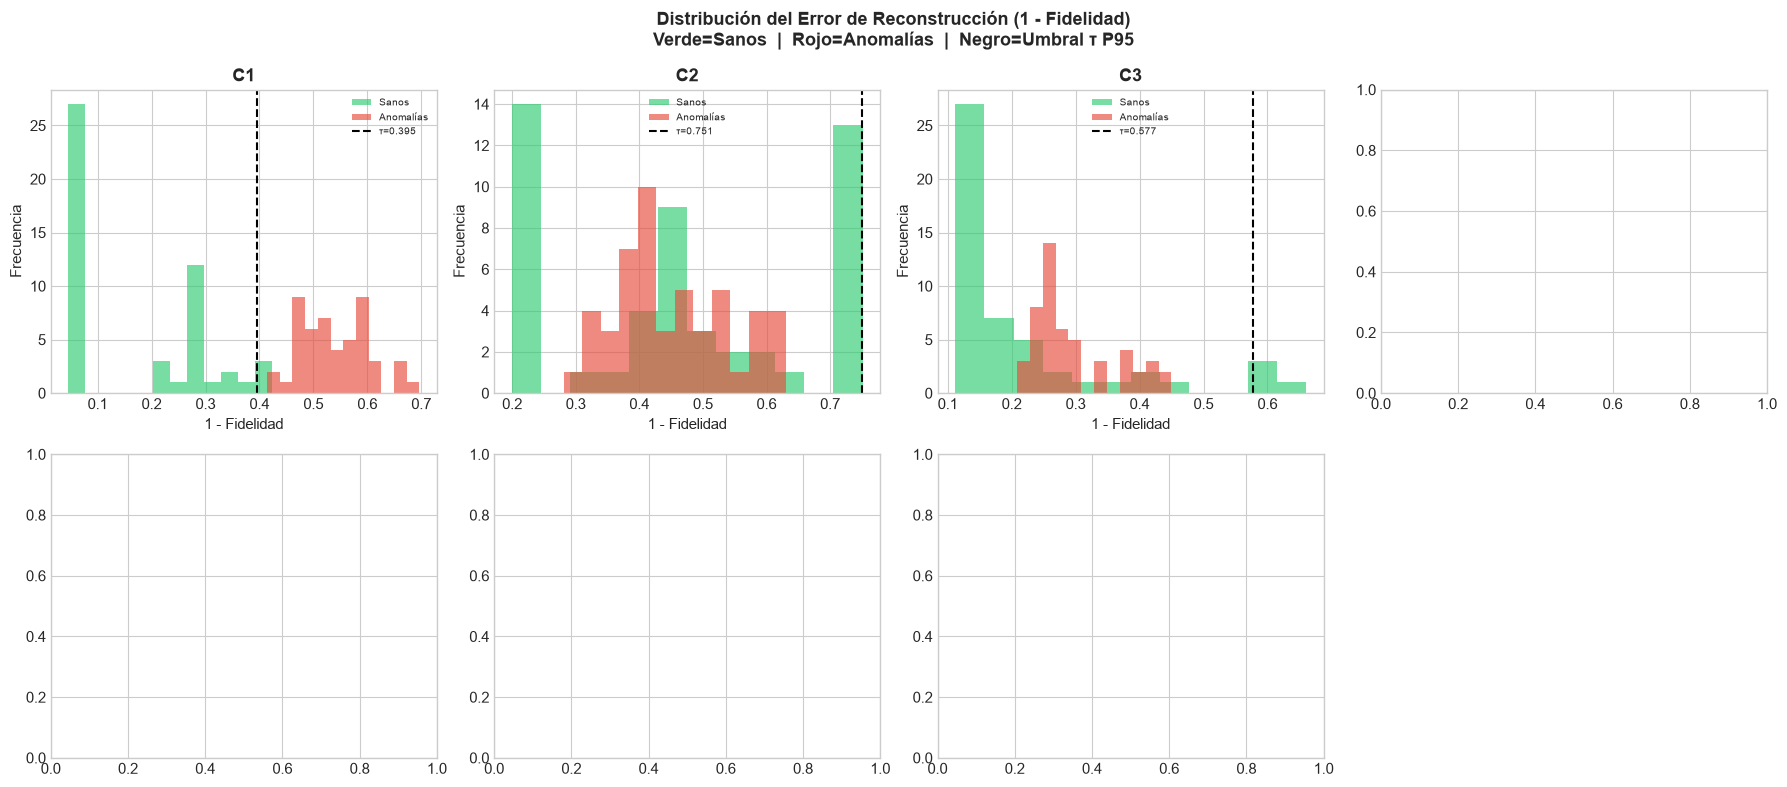

Guardado: histogramas_anomalias.png


In [19]:
# ==============================================================================
# CELDA 11: HISTOGRAMAS — DISTRIBUCIÓN DE ERRORES SANOS vs FALLAS
# ==============================================================================

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
fig.suptitle(f'Distribución del Error de Reconstrucción (1 - Fidelidad)\n'
             f'Verde=Sanos  |  Rojo={etiqueta_anom}  |  Negro=Umbral τ P95',
             fontsize=13, fontweight='bold')

for idx, (nombre, (err_s, err_a, tau)) in enumerate(scores.items()):
    ax = axes[idx]
    ax.hist(err_s, bins=15, alpha=0.65, color='#2ecc71', label='Sanos')
    ax.hist(err_a, bins=15, alpha=0.65, color='#e74c3c', label=etiqueta_anom)
    ax.axvline(tau, color='black', ls='--', lw=1.5, label=f'τ={tau:.3f}')
    ax.set_title(nombre.split(':')[0], fontweight='bold')
    ax.set_xlabel('1 - Fidelidad'); ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=7)

for j in range(len(scores), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()


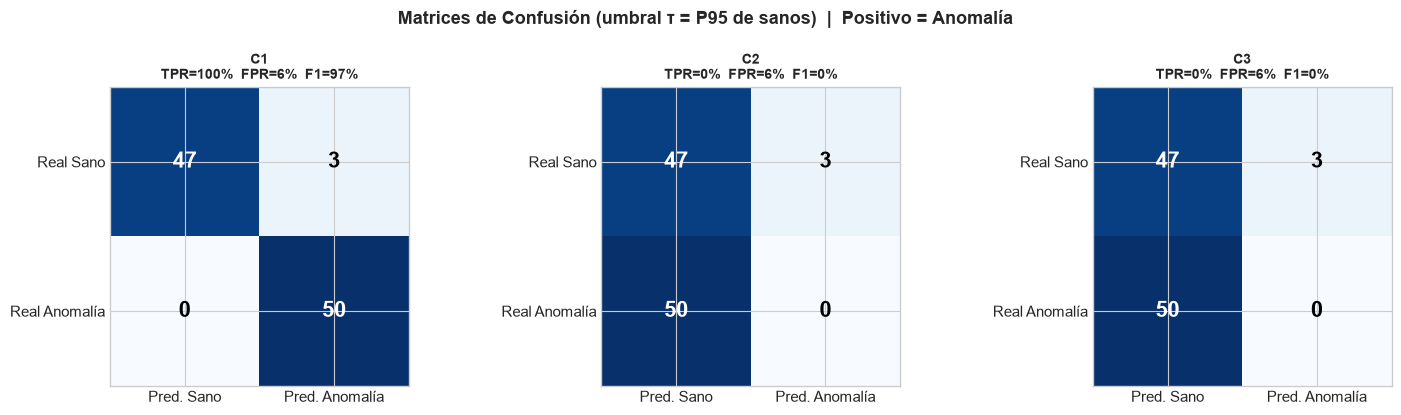

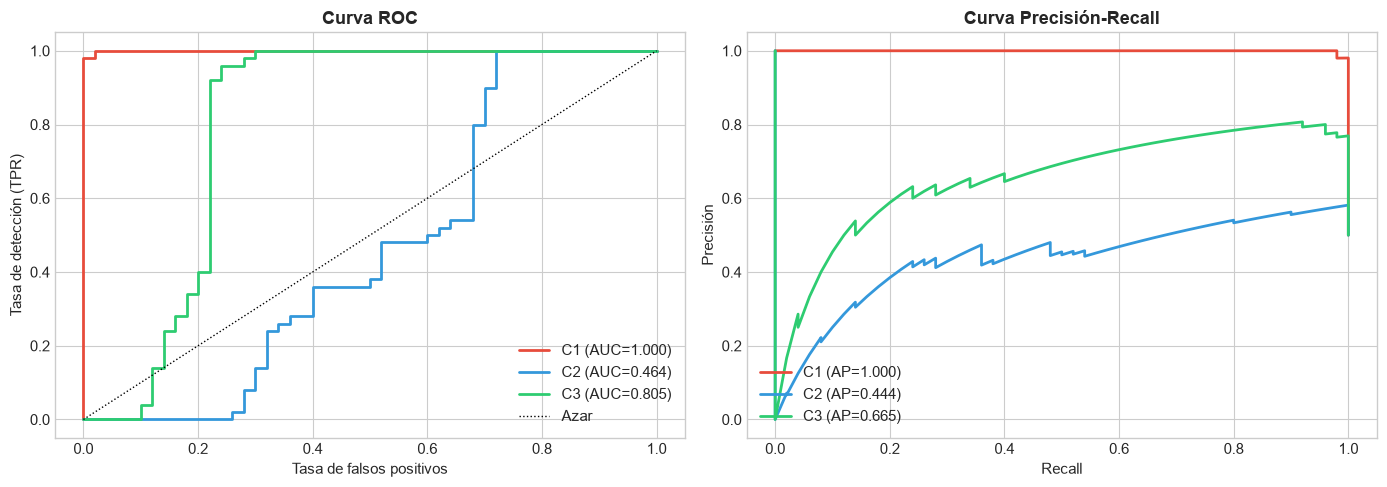

Guardado: matrices_confusion.png, roc_pr_circuitos.png


In [20]:
# ==============================================================================
# CELDA 11b: MATRICES DE CONFUSIÓN, CURVAS ROC Y PRECISIÓN-RECALL
# ==============================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

n = len(scores)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4.2))
axes = np.atleast_1d(axes)
fig.suptitle('Matrices de Confusión (umbral τ = P95 de sanos)  |  Positivo = Anomalía',
             fontsize=13, fontweight='bold')
for ax, (nombre, (es, ea, tau)) in zip(axes, scores.items()):
    m  = metricas_deteccion(es, ea, tau)
    cm = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]])
    ax.imshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center', fontsize=16, fontweight='bold',
                    color='white' if cm[r, c] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred. Sano', 'Pred. Anomalía'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Real Sano', 'Real Anomalía'])
    ax.set_title(f"{nombre.split(':')[0]}\nTPR={m['TPR']:.0f}%  FPR={m['FPR']:.0f}%  F1={m['F1']:.0f}%",
                 fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for (nombre, (es, ea, tau)), col in zip(scores.items(), COLORES):
    y = np.r_[np.zeros(len(es)), np.ones(len(ea))]; s = np.r_[es, ea]
    fpr, tpr, _ = roc_curve(y, s)
    pr, rc, _   = precision_recall_curve(y, s)
    lbl = nombre.split(':')[0]
    ax1.plot(fpr, tpr, color=col, lw=2, label=f"{lbl} (AUC={roc_auc_score(y, s):.3f})")
    ax2.plot(rc, pr, color=col, lw=2, label=f"{lbl} (AP={average_precision_score(y, s):.3f})")
ax1.plot([0, 1], [0, 1], 'k:', lw=1, label='Azar')
ax1.set_xlabel('Tasa de falsos positivos'); ax1.set_ylabel('Tasa de detección (TPR)')
ax1.set_title('Curva ROC', fontweight='bold'); ax1.legend(loc='lower right')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precisión')
ax2.set_title('Curva Precisión-Recall', fontweight='bold'); ax2.legend(loc='lower left')
plt.tight_layout()
plt.show()


TABLA RESUMEN COMPLETA:
                        Profundidad  Nº Parámetros  Total Puertas  Fid. Sanos (%)  Fid. Anomalías (%)  Separación (pp)  MSE Proxy (sanos)  Detección (%)  FPR (%)  Precisión (%)  F1 (%)  Exactitud (%)  Exact. Bal. (%)    MCC  AUC-ROC     AP  TP  FP  TN  FN
Circuito                                                                                                                                                                                                                                                       
C1: Rot+Stride                   14             42             29           83.59               45.85            37.75             0.1641          100.0      6.0           94.3    97.1           97.0             97.0  0.942    1.000  1.000  50   3  47   0
C2: BasicEntangler                2             14              2           53.21               54.81            -1.60             0.4679            0.0      6.0            0.0     0.0           47.0         

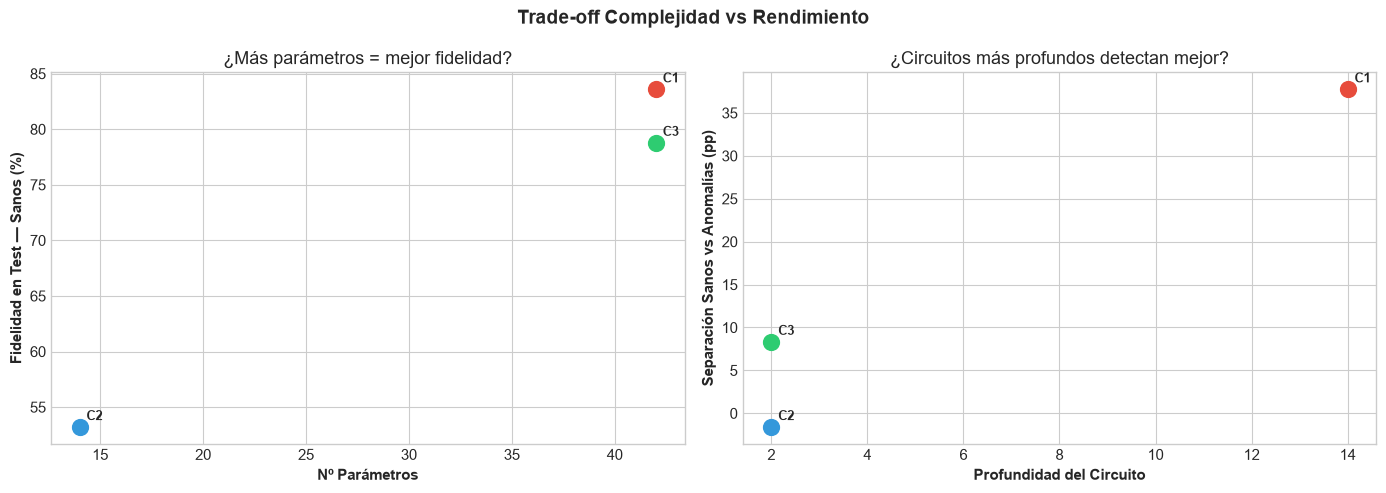

Guardado: scatter_complejidad.png


In [21]:
# ==============================================================================
# CELDA 12: TABLA RESUMEN + SCATTER — COMPLEJIDAD vs RENDIMIENTO
# ==============================================================================

df_final = df_comp[['Profundidad','Nº Parámetros','Total Puertas']].join(df_eval)
print("TABLA RESUMEN COMPLETA:")
print(df_final.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Trade-off Complejidad vs Rendimiento', fontsize=14, fontweight='bold')

for (nombre, col) in zip(df_final.index, COLORES):
    r   = df_final.loc[nombre]
    etq = nombre.split(':')[0]
    ax1.scatter(r['Nº Parámetros'], r['Fid. Sanos (%)'], color=col, s=130, zorder=5)
    ax1.annotate(etq, (r['Nº Parámetros'], r['Fid. Sanos (%)']),
                 textcoords='offset points', xytext=(5,5), fontsize=9, fontweight='bold')
    ax2.scatter(r['Profundidad'], r['Separación (pp)'], color=col, s=130, zorder=5)
    ax2.annotate(etq, (r['Profundidad'], r['Separación (pp)']),
                 textcoords='offset points', xytext=(5,5), fontsize=9, fontweight='bold')

ax1.set_xlabel('Nº Parámetros', fontweight='bold')
ax1.set_ylabel('Fidelidad en Test — Sanos (%)', fontweight='bold')
ax1.set_title('¿Más parámetros = mejor fidelidad?')
ax2.set_xlabel('Profundidad del Circuito', fontweight='bold')
ax2.set_ylabel('Separación Sanos vs Anomalías (pp)', fontweight='bold')
ax2.set_title('¿Circuitos más profundos detectan mejor?')

plt.tight_layout()
plt.show()


---
## 🧪 9. Laboratorio de Experimentación para C1

Cambia **solo** los parámetros del bloque `PARAMETROS` (capas, trash qubits, épocas, tipo de rotación y entrelazamiento) y ejecuta la celda.
Corre varias semillas y reporta, además de la fidelidad, la **brecha train-val** (señal de sobreentrenamiento) y el **AUC** (detección sin depender del umbral).

**Cómo leer los resultados**
- `Fid sanos` alta = conserva información (buena reconstrucción). Baja al subir `TRASH` (se comprime más).
- `Detec (TPR) %` / `AUC` alta = separa bien sanos de anomalías sintéticas.
- `Gap tr-val` grande (> ~3 pp) = sobreentrenamiento.
- Hallazgo previo: más capas con 1 trash qubit sube la fidelidad pero **empeora** la detección (el circuito también comprime anomalías). Subir `TRASH` a 2 es lo que más mejora la separación.
- `FPR %` = sanos marcados como anomalía (con τ = P95 ronda 5 %). `Prec`, `F1`, `Exact.Bal`, `MCC` (−1 a 1) y `AP` resumen el balance entre aciertos y falsas alarmas.
- `TP/FP/TN/FN` = matriz de confusión promediada entre semillas (positivo = anomalía).


In [23]:
# ==============================================================================
# CELDA 13: LABORATORIO C1 — mueve estos parametros y ejecuta
# ==============================================================================
import time
from sklearn.metrics import roc_auc_score

# ───────────────────────────── PARAMETROS ─────────────────────────────────────
PARAMETROS = dict(
    n_layers = 3,        # etapas/capas del ansatz            (prueba 2, 3, 4, 6, 8)
    trash    = 2,        # trash qubits (K = 7 - trash)       (prueba 1, 2, 3)
    epochs   = 20,       # epocas
    lr       = 0.12,     # learning rate de Adam
    batch    = 25,
    n_samp   = 100,      # registros de entrenamiento         (prueba 100, 200, 400)
    rot      = 'rot',    # 'rot' | 'ryrz' | 'ryrzry'   (rotacion por qubit)
    ent      = 'stride', # 'ring' | 'stride' | 'ring+stride'   (entrelazamiento)
)
SEMILLAS = [42, 1, 2]    # mas semillas = resultados mas fiables (y mas lento)

# Barrido opcional: lista de dicts que sobreescriben PARAMETROS. [] = solo PARAMETROS.
BARRIDO = [
    dict(n_layers=2, trash=1, rot='ryrz', ent='ring'),   # baseline original
    dict(n_layers=4, trash=1),
    dict(n_layers=4, trash=2),
    dict(n_layers=6, trash=2),
]
# ──────────────────────────────────────────────────────────────────────────────

def hacer_ansatz_c1(rot, ent):
    npar = {'ryrz': 2, 'rot': 3, 'ryrzry': 3}[rot]
    def ansatz(weights, wires):
        n = len(wires)
        for l, layer in enumerate(weights):
            for i, w in enumerate(wires):
                if rot == 'rot':
                    qml.Rot(layer[i, 0], layer[i, 1], layer[i, 2], wires=w)
                elif rot == 'ryrz':
                    qml.RY(layer[i, 0], wires=w); qml.RZ(layer[i, 1], wires=w)
                else:
                    qml.RY(layer[i, 0], wires=w); qml.RZ(layer[i, 1], wires=w); qml.RY(layer[i, 2], wires=w)
            if ent in ('ring', 'ring+stride'):           # anillo de vecinos
                for i in range(n - 1): qml.CNOT(wires=[wires[i], wires[i + 1]])
                qml.CNOT(wires=[wires[-1], wires[0]])
            if ent == 'stride':                          # alcance variable por capa
                r = (l % (n - 1)) + 1
                for i in range(n): qml.CNOT(wires=[wires[i], wires[(i + r) % n]])
            if ent == 'ring+stride':
                r = (l % (n - 2)) + 2
                for i in range(n): qml.CNOT(wires=[wires[i], wires[(i + r) % n]])
    return ansatz, npar

def experimento_c1(n_layers, trash, epochs, lr, batch, n_samp, rot, ent, seed, n_eval=200):
    np.random.seed(seed)
    ans, npar = hacer_ansatz_c1(rot, ent)
    dev = qml.device('default.qubit', wires=TOTAL_QUBITS)
    tw = list(range(TOTAL_QUBITS - trash, TOTAL_QUBITS))

    @qml.qnode(dev)
    def qn(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(TOTAL_QUBITS), normalize=False)
        ans(w, wires=range(TOTAL_QUBITS))
        return qml.probs(wires=tw)

    W = pnp.random.uniform(0, 2*np.pi, size=(n_layers, TOTAL_QUBITS, npar), requires_grad=True)
    Xd = X_train_q[:n_samp]
    opt = qml.AdamOptimizer(stepsize=lr)
    for ep in range(epochs):
        perm = np.random.permutation(len(Xd))
        for i in range(0, len(Xd), batch):
            B = pnp.array(Xd[perm[i:i+batch]], requires_grad=False)
            W = opt.step(lambda w: 1.0 - pnp.mean(qn(B, w)[:, 0]), W)

    f = lambda X: np.array(qn(pnp.array(X, requires_grad=False), W)[:, 0])
    f_tr, f_val = f(Xd).mean()*100, f(X_val_q[:n_eval]).mean()*100
    if USAR_FALLAS_REALES:
        X_fa, _ = muestra_estratificada_fallas(X_fallas_real_all, tipos_fallas_real_all, n_total=n_eval, seed=EVAL_SEED)
    else:
        X_fa = hacer_anomalias(X_test_q[:n_eval])
    fs = f(X_test_q[:n_eval]); fa = f(X_fa)
    m = metricas_deteccion(1 - fs, 1 - fa)   # definida en la celda 10 (umbral P95 sobre sanos)
    return dict(tr=f_tr, val=f_val, san=fs.mean()*100, anom=fa.mean()*100, **m)

filas = []
configs = BARRIDO if BARRIDO else [dict()]
for ov in configs:
    cfg = {**PARAMETROS, **ov}
    t0 = time.time()
    rs = [experimento_c1(seed=s, **cfg) for s in SEMILLAS]
    m = {k: float(np.mean([r[k] for r in rs])) for k in rs[0]}
    filas.append({
        'Config': f"L={cfg['n_layers']} T={cfg['trash']} {cfg['rot']}/{cfg['ent']} ep={cfg['epochs']} n={cfg['n_samp']}",
        'Params': cfg['n_layers'] * TOTAL_QUBITS * {'ryrz': 2, 'rot': 3, 'ryrzry': 3}[cfg['rot']],
        'Fid train %': round(m['tr'], 1), 'Fid val %': round(m['val'], 1),
        'Gap tr-val': round(m['tr'] - m['val'], 1),
        'Fid sanos %': round(m['san'], 1), 'Fid anom %': round(m['anom'], 1),
        'Sep (pp)': round(m['san'] - m['anom'], 1),
        'Detec (TPR) %': round(m['TPR'], 1), 'FPR %': round(m['FPR'], 1),
        'Prec %': round(m['Precision'], 1), 'F1 %': round(m['F1'], 1),
        'Exact.Bal %': round(m['Exactitud_bal'], 1), 'MCC': round(m['MCC'], 3),
        'AUC': round(m['AUC_ROC'], 3), 'AP': round(m['AP'], 3),
        'TP/FP/TN/FN': f"{m['TP']:.0f}/{m['FP']:.0f}/{m['TN']:.0f}/{m['FN']:.0f}",
        'Seg': round(time.time() - t0),
    })
    print(f"  listo: {filas[-1]['Config']}  ->  sanos={m['san']:.1f}%  detec={m['TPR']:.0f}%  FPR={m['FPR']:.0f}%  F1={m['F1']:.0f}%  AUC={m['AUC_ROC']:.3f}")

df_lab = pd.DataFrame(filas).set_index('Config')
print('\n', df_lab.T.to_string())  # transpuesta: una columna por configuración
print('\nPara adoptar una config: copia n_layers/trash a CFG_POR_CIRCUITO (celda 8) y, si cambias rot/ent, edita ansatz_c1 (celda 3).')


  listo: L=2 T=1 ryrz/ring ep=20 n=100  ->  sanos=91.3%  detec=62%  FPR=5%  F1=70%  AUC=0.946
  listo: L=4 T=1 rot/stride ep=20 n=100  ->  sanos=93.2%  detec=35%  FPR=5%  F1=36%  AUC=0.814
  listo: L=4 T=2 rot/stride ep=20 n=100  ->  sanos=80.0%  detec=88%  FPR=5%  F1=90%  AUC=0.984
  listo: L=6 T=2 rot/stride ep=20 n=100  ->  sanos=86.9%  detec=98%  FPR=5%  F1=96%  AUC=0.992

 Config        L=2 T=1 ryrz/ring ep=20 n=100 L=4 T=1 rot/stride ep=20 n=100 L=4 T=2 rot/stride ep=20 n=100 L=6 T=2 rot/stride ep=20 n=100
Params                                   28                             84                             84                            126
Fid train %                            89.7                           91.9                           77.5                           85.1
Fid val %                              90.0                           92.3                           77.2                           85.4
Gap tr-val                             -0.3                           -

---
## 🎓 8. Conclusiones y Recomendaciones

| Circuito | Cuándo usarlo |
|----------|---------------|
| C1: Rot+Stride | Versión mejorada del baseline (Rot + CNOT de alcance variable) |
| C2: BasicEntangler | Mínimo de parámetros — máxima velocidad |
| C3: StronglyEntangling | **Mejor balance** expresividad/velocidad |
| C4: Hardware-Efficient | Para correr en hardware real (IBM Q) |
| C5: Two-Design | Exploración uniforme del espacio de estados |
| C6: Ising-Inspired | Datos con estructura de acoplamiento físico |
| C7: Deep Alternating | Máxima expresividad — riesgo de Barren Plateaus |

### Sobre la pregunta del decoder
- **`1 - Fidelidad`** del trash qubit ES el error de reconstrucción cuántico.
- No necesitas un decoder físico separado para medir cuánta info se pierde.
- El **MSE Proxy** calculado arriba conecta esta métrica con el lenguaje clásico.
- Recomendación final: **C3 StronglyEntangling** como circuito principal, **C1** como baseline comparativo.
